<a href="https://colab.research.google.com/github/chaimaao0/ml-data-science-internship/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load the Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("/content/sample_data/Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Clean the Data
`TotalCharges` is stored as text because a few rows are blank. We convert it to numbers; the blank values become `NaN`.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]].head()

Missing TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN


In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## 3. Class Imbalance
Let's look at how many customers churn.

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


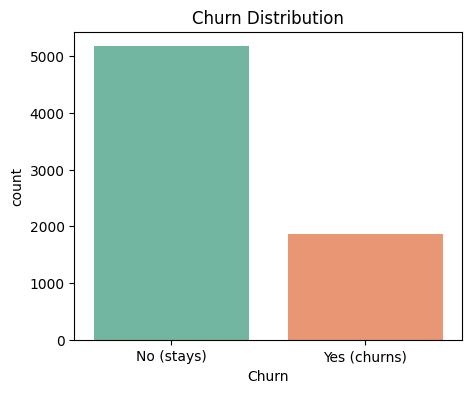

In [5]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn", hue="Churn", palette="Set2", legend=False)
plt.xticks([0, 1], ["No (stays)", "Yes (churns)"])
plt.title("Churn Distribution")
plt.show()

## 4. Split and Encode


In [6]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 0.265 | test: 0.265


In [7]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()   # text columns
num_cols = X.select_dtypes(include="number").columns.tolist()   # numeric columns

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", "passthrough", num_cols),
])

print("Categorical columns:", len(cat_cols))
print("Numeric columns    :", num_cols)

Categorical columns: 15
Numeric columns    : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 5. Build the Models


In [8]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 2))

models = {
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                         class_weight="balanced", random_state=42, n_jobs=-1)),
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocessor),
        ("model", XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                                scale_pos_weight=scale_pos_weight, eval_metric="logloss",
                                random_state=42)),
    ]),
}

scale_pos_weight: 2.77


## 6. Cross-Validation

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name:<14} CV ROC-AUC: {scores.mean():.4f} (+/- {scores.std():.4f})")

Random Forest  CV ROC-AUC: 0.8474 (+/- 0.0092)
XGBoost        CV ROC-AUC: 0.8478 (+/- 0.0123)


## 7. Train and Evaluate on the Test Set

In [10]:
for name, model in models.items():
    model.fit(X_train, y_train)
preds = {name: m.predict(X_test) for name, m in models.items()}
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

In [11]:
results = pd.DataFrame({
    name: {
        "ROC-AUC": roc_auc_score(y_test, probs[name]),
        "Precision (churn)": precision_score(y_test, preds[name]),
        "Recall (churn)": recall_score(y_test, preds[name]),
        "F1-score (churn)": f1_score(y_test, preds[name]),
    }
    for name in models
}).T

results.round(4)

,ROC-AUC,Precision (churn),Recall (churn),F1-score (churn)
Random Forest,0.8428,0.5296,0.7888,0.6337
XGBoost,0.8454,0.5166,0.7914,0.6251


In [12]:
for name in models:
    print("===", name, "===")
    print(classification_report(y_test, preds[name], target_names=["Stays", "Churns"]))

=== Random Forest ===
              precision    recall  f1-score   support

       Stays       0.91      0.75      0.82      1035
      Churns       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409

=== XGBoost ===
              precision    recall  f1-score   support

       Stays       0.91      0.73      0.81      1035
      Churns       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [13]:
for name in models:
    auc = results.loc[name, "ROC-AUC"]
    print(f"{name:<14} ROC-AUC = {auc:.4f} -> {'above 0.80' if auc > 0.80 else 'BELOW 0.80'}")

Random Forest  ROC-AUC = 0.8428 -> above 0.80
XGBoost        ROC-AUC = 0.8454 -> above 0.80


## 8. ROC Curves

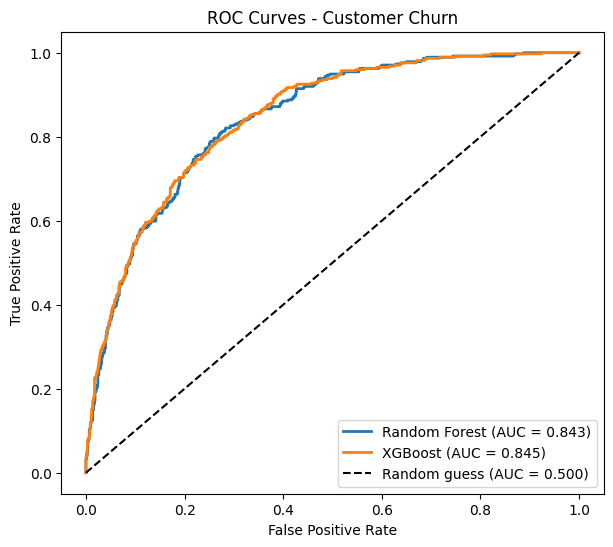

In [14]:
plt.figure(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.500)")
plt.title("ROC Curves - Customer Churn")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

## 9. Confusion Matrices

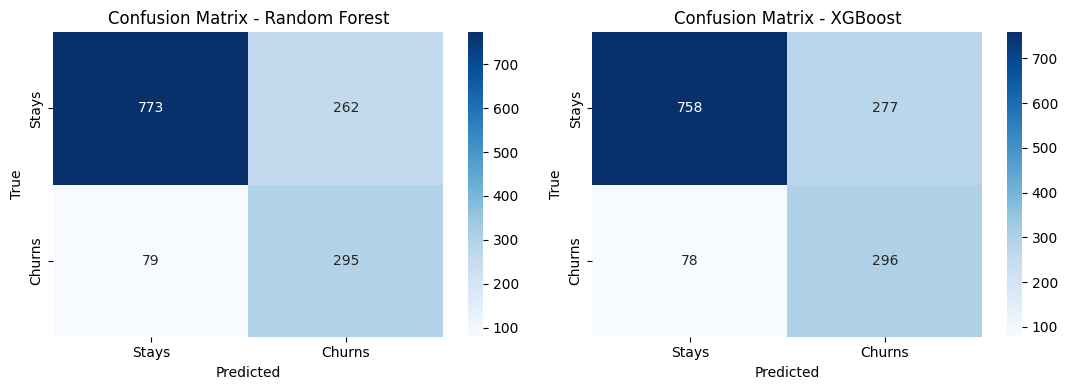

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, models):
    sns.heatmap(confusion_matrix(y_test, preds[name]), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Stays", "Churns"], yticklabels=["Stays", "Churns"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

## 10. Top 10 Feature Importances
Which columns help the model the most? The names of the one-hot columns look like `Contract_Month-to-month`: the original column, then the category.

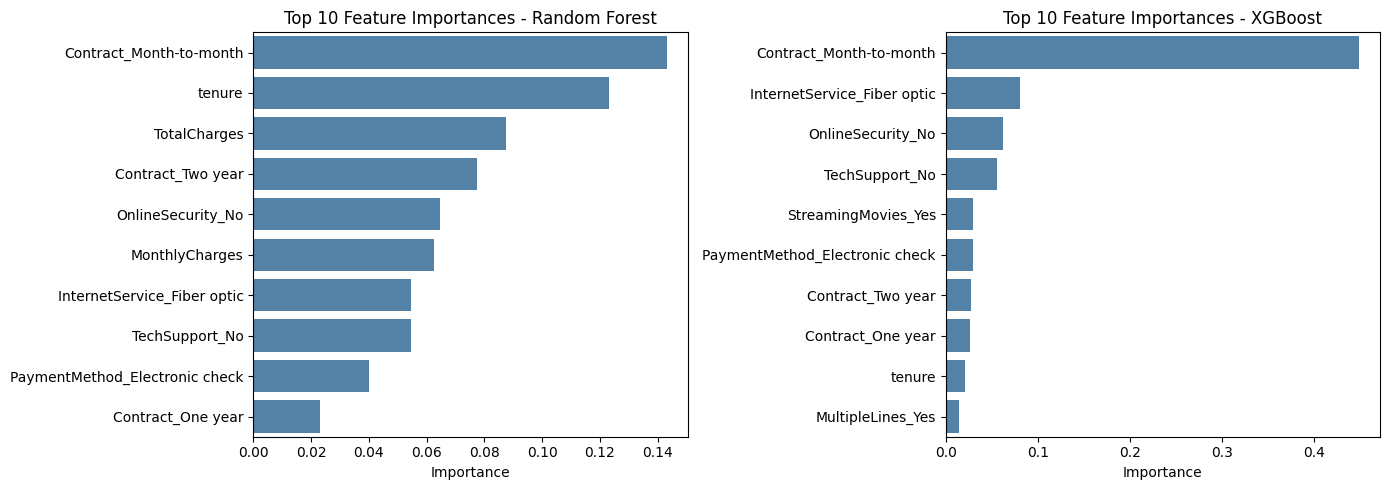

In [16]:
feature_names = models["Random Forest"].named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__")[1] for n in feature_names]   # remove the "cat__" / "num__" prefix

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, models):
    importances = pd.Series(models[name].named_steps["model"].feature_importances_, index=feature_names)
    top10 = importances.sort_values(ascending=False).head(10)
    sns.barplot(x=top10.values, y=top10.index, color="steelblue", ax=ax)
    ax.set_title(f"Top 10 Feature Importances - {name}")
    ax.set_xlabel("Importance")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [17]:
display(results.round(4))
best = results["ROC-AUC"].idxmax()
print("Best ROC-AUC:", best)

,ROC-AUC,Precision (churn),Recall (churn),F1-score (churn)
Random Forest,0.8428,0.5296,0.7888,0.6337
XGBoost,0.8454,0.5166,0.7914,0.6251


Best ROC-AUC: XGBoost


Both models passed the 0.80 target. On the test set, Random Forest reached a ROC-AUC of 0.8428 and XGBoost 0.8454. In 5-fold cross-validation they scored 0.8474 and 0.8478. XGBoost is slightly higher, but the gap (about 0.003) is smaller than the variation between folds (about 0.01), so the two models perform about the same.

Thanks to class weighting, both models find most of the customers who leave: recall for the churn class is about 0.79 (295 of 374 churners for Random Forest and 296 of 374 for XGBoost). The price is a lower precision of about 0.52 to 0.53, which means about half of the customers flagged as churners actually stay (262 and 277 false alarms). The accuracy is 75-76%, barely above the 73.5% we would get by always predicting "stays". This is why ROC-AUC, precision and recall are better scores than accuracy for this problem.

The feature importance charts show that `Contract_Month-to-month` is the most important feature for both models. Other important features are `tenure`, `TotalCharges`, `MonthlyCharges`, `InternetService_Fiber optic`, `OnlineSecurity_No`, `TechSupport_No` and `PaymentMethod_Electronic check`. The charts show which features the models rely on most, not whether they increase or decrease churn.